# Unsupervised Machine Learning - Sample Data

## Project overview
This notebook explores how unsupervised machine learning can help group oil and gas wells with similar operating and reservoir characteristics.

The workflow covers exploratory data analysis, feature scaling, K-Means clustering, cluster evaluation with the elbow method and silhouette score, and dimensionality reduction with Principal Component Analysis (PCA).

> **Dataset requirement:** Place `sample_oil_gas_well_dataset.csv` in the same folder as this notebook before running the analysis.


## Learning objectives

- Inspect and summarize a tabular dataset (sample data) with pandas.
- Explore relationships between oil production and water cut.
- Understand Euclidean distance and why feature scaling matters.
- Fit K-Means models and interpret cluster profiles.
- Compare candidate cluster counts using inertia and silhouette scores.
- Use PCA to visualize high-dimensional data in two dimensions.

## Workflow

1. Load and inspect the data.
2. Explore oil-well production characteristics.
3. Review distance and standardization concepts.
4. Build and interpret K-Means clusters.
5. Evaluate the number of clusters.
6. Visualize clusters and centroids with PCA.


## 1. Load and Inspect the Dataset

Load the well dataset and review its dimensions, data types, missing values, and descriptive statistics. Resolve data-quality issues before interpreting clustering results.

In [3]:
import pandas as pd
import matplotlib.pyplot as plt

df = pd.read_csv("sample_oil_gas_well_dataset.csv")
print(df.head())

print("\nDataset dimensions:")
print(df.shape)

print("\nDataset information:")
df.info()

print("\nMissing values:")
print(df.isnull().sum())

print("\nSummary statistics:")
print(df.describe())

  well_id  oil_rate_bopd  water_cut_pct  gor_scf_per_bbl  \
0    W001           64.7           85.7           1062.5   
1    W002          273.6           41.5           1098.3   
2    W003           62.8           82.0           1537.0   
3    W004          213.0           49.6           1054.4   
4    W005          387.1           18.1            986.5   

   reservoir_pressure_bar  porosity_pct  permeability_mD  temperature_C  \
0                   128.3          14.5             48.3           77.7   
1                   211.4          16.5             39.6           74.1   
2                   148.8          12.7             38.2           77.0   
3                   180.9          15.9             41.2           85.4   
4                   254.8          22.7            172.2           89.5   

   water_rate_bwpd  
0            389.2  
1            194.2  
2            285.7  
3            209.3  
4             85.5  

Dataset dimensions:
(60, 9)

Dataset information:
<class 'pan

## 2. Exploratory Data Analysis: Oil Rate vs. Water Cut

Plot oil production against water cut to inspect their relationship and identify broad patterns or potential outliers.

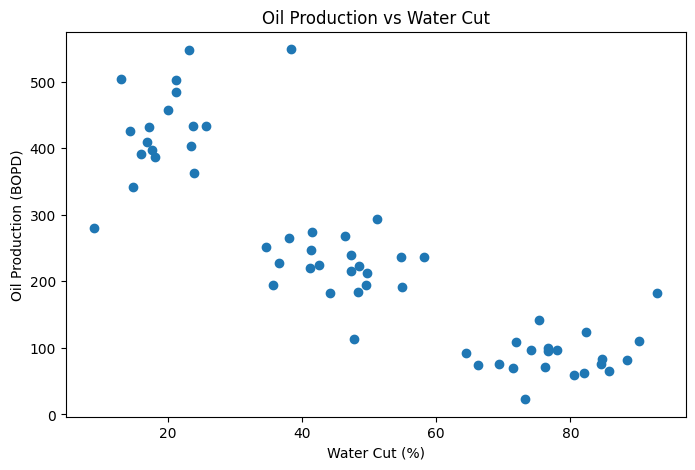

In [5]:
plt.figure(figsize=(8, 5))

plt.scatter(
    df["water_cut_pct"],
    df["oil_rate_bopd"]
)

plt.xlabel("Water Cut (%)")
plt.ylabel("Oil Production (BOPD)")
plt.title("Oil Production vs Water Cut")

plt.show()

## 3. Distance Between Wells

Euclidean distance measures the straight-line distance between two observations in feature space. Here, the two values are illustrative rather than rows selected from the dataset.

In [ ]:
import numpy as np


well_A = np.array([100, 80])
well_B = np.array([200, 50])

distance = np.linalg.norm(well_A - well_B)

print("Distance between the wells:", round(distance, 2))

Distance between the wells: 104.4


## 4. Why Feature Scaling Matters

Features measured on different scales can contribute unequally to distance calculations. Standardization places each feature on a comparable scale by centering it and scaling it to unit variance.

In [6]:

from sklearn.preprocessing import StandardScaler
import numpy as np

wells = np.array([
    [100, 80],
    [200, 50],
    [500, 10]
])

scaler = StandardScaler()
wells_scaled = scaler.fit_transform(wells)

print(wells_scaled.round(2))

[[-0.98  1.16]
 [-0.39  0.12]
 [ 1.37 -1.28]]


### Changing values for testing

This shows how Euclidean distance changes when the input values change.

In [8]:
import numpy as np

well_A = np.array([300, 40])
well_B = np.array([100, 50])

distance = np.linalg.norm(well_A - well_B)

print("Distance between wells:", round(distance, 2))

Distance between wells: 200.25


## 5. Build a K-Means Clustering Model

Select oil rate, water cut, gas–oil ratio (GOR), and reservoir pressure as clustering features. Standardize these features before fitting K-Means, because the algorithm relies on distances.

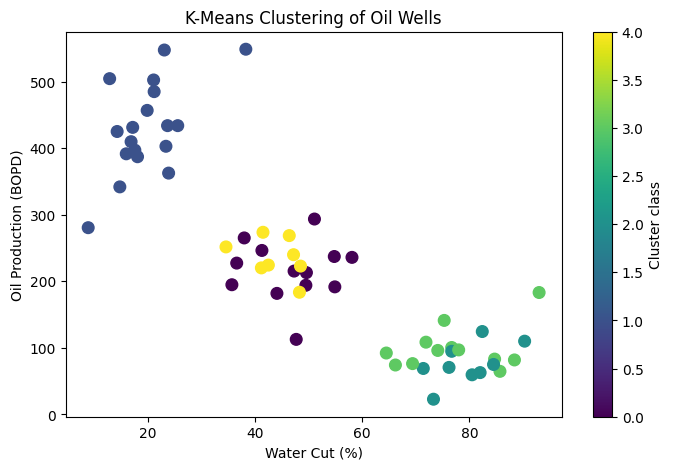

In [9]:
import pandas as pd
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
import matplotlib.pyplot as plt

df = pd.read_csv("sample_oil_gas_well_dataset.csv")

features = ["oil_rate_bopd", "water_cut_pct", "gor_scf_per_bbl", "reservoir_pressure_bar"]
X = df[features]
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

kmeans = KMeans(n_clusters=5, random_state=42, n_init=15)
df["cluster"] = kmeans.fit_predict(X_scaled)

plt.figure(figsize=(8, 5))

plt.scatter(
    df["water_cut_pct"],
    df["oil_rate_bopd"],
    c=df["cluster"],
    cmap="viridis",
    s=70
)

plt.xlabel("Water Cut (%)")
plt.ylabel("Oil Production (BOPD)")
plt.title("K-Means Clustering of Oil Wells")
plt.colorbar(label="Cluster class")
plt.show()

### checking Cluster Assignments

Fit the five-cluster model and inspect the assigned cluster labels alongside selected well properties.

In [10]:
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
import matplotlib.pyplot as plt

features = [
    "oil_rate_bopd",
    "water_cut_pct",
    "gor_scf_per_bbl",
    "reservoir_pressure_bar"
]

X = df[features]

scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

# I put cluster to 5
kmeans = KMeans(n_clusters=5, random_state=42, n_init=15)

df["cluster"] = kmeans.fit_predict(X_scaled)

print(df[["well_id", "oil_rate_bopd",
          "water_cut_pct", "cluster"]].head(15))

   well_id  oil_rate_bopd  water_cut_pct  cluster
0     W001           64.7           85.7        3
1     W002          273.6           41.5        4
2     W003           62.8           82.0        2
3     W004          213.0           49.6        0
4     W005          387.1           18.1        1
5     W006           92.2           64.5        3
6     W007           81.8           88.4        3
7     W008           83.1           84.7        3
8     W009          425.0           14.3        1
9     W010          239.9           47.2        4
10    W011          194.8           35.7        0
11    W012           59.5           80.5        2
12    W013          112.7           47.7        0
13    W014          100.5           76.7        3
14    W015          237.2           54.8        0


### Visualize the Clusters

Display the cluster assignments on an oil-rate-versus-water-cut plot. The visualization shows only two of the four input features, so some separation may not be visible in this projection.

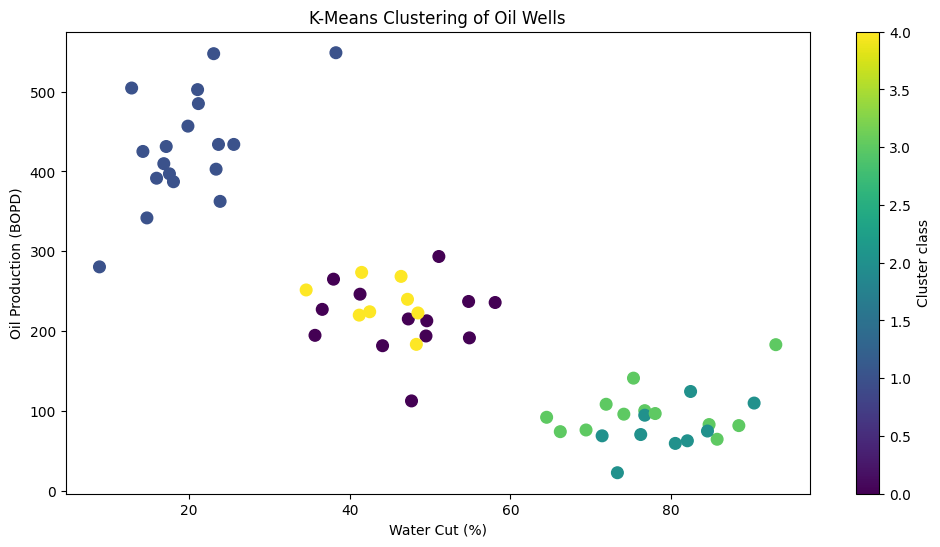

In [11]:
plt.figure(figsize=(12, 6))

plt.scatter(
    df["water_cut_pct"],
    df["oil_rate_bopd"],
    c=df["cluster"],
    cmap="viridis",
    s=70
)

plt.xlabel("Water Cut (%)")
plt.ylabel("Oil Production (BOPD)")
plt.title("K-Means Clustering of Oil Wells")
plt.colorbar(label="Cluster class")
plt.show()

### Summarize Cluster Characteristics

Count wells in each cluster and compare the mean values of the features used for clustering. These summaries help describe the groups; they do not establish causal relationships.

In [12]:
print(df["cluster"].value_counts().sort_index())
cluster_summary = df.groupby("cluster")[[
    "oil_rate_bopd",
    "water_cut_pct",
    "gor_scf_per_bbl",
    "reservoir_pressure_bar"
]].mean().round(2)

print(cluster_summary)

cluster
0    13
1    18
2     9
3    12
4     8
Name: count, dtype: int64
         oil_rate_bopd  water_cut_pct  gor_scf_per_bbl  reservoir_pressure_bar
cluster                                                                       
0               216.04          46.82           959.82                  177.99
1               430.06          19.83           850.28                  243.47
2                76.56          79.70          1671.39                  140.19
3                99.88          77.32          1233.88                  137.00
4               235.55          43.78          1355.94                  204.19


## 6. Principal Component Analysis (PCA)

PCA projects the standardized four-feature dataset onto two principal components. The scatter plot uses these components for visualization while coloring points by their K-Means cluster labels.

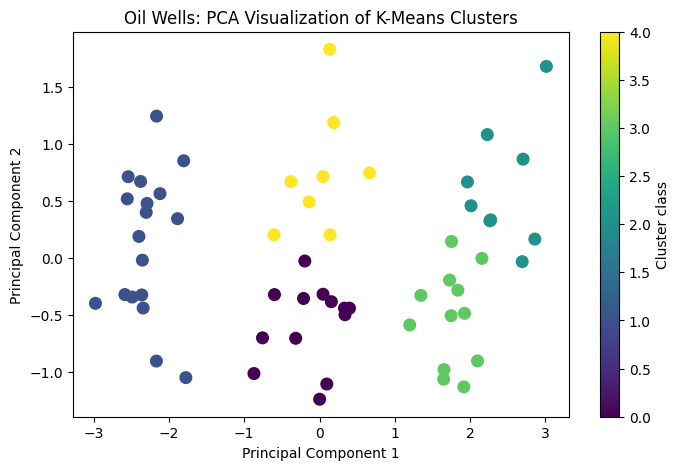

Variance explained: 93.03 %


In [13]:
from sklearn.decomposition import PCA
import matplotlib.pyplot as plt

pca = PCA(n_components=2)
X_pca = pca.fit_transform(X_scaled)

plt.figure(figsize=(8, 5))
plt.scatter(
    X_pca[:, 0],
    X_pca[:, 1],
    c=df["cluster"],
    cmap="viridis",
    s=70
)

plt.xlabel("Principal Component 1")
plt.ylabel("Principal Component 2")
plt.title("Oil Wells: PCA Visualization of K-Means Clusters")
plt.colorbar(label="Cluster class")
plt.show()

print(
    "Variance explained:",
    round(pca.explained_variance_ratio_.sum() * 100, 2),
    "%"
)

### Interpret PCA Feature Loadings

The loadings indicate how the original standardized features contribute to each principal component. Interpret their signs and magnitudes together with the explained-variance ratios.

In [14]:
import pandas as pd

loadings = pd.DataFrame(
    pca.components_.T,
    index=features,
    columns=["PC1", "PC2"]
)

print(loadings.round(3))

                          PC1    PC2
oil_rate_bopd          -0.527  0.127
water_cut_pct           0.529 -0.105
gor_scf_per_bbl         0.440  0.848
reservoir_pressure_bar -0.499  0.504


### Inspect PCA Coordinates and Cluster Labels

Combine each well's two PCA coordinates with its well ID and cluster assignment for further inspection.

In [15]:
pca_results = pd.DataFrame(
    X_pca,
    columns=["PC1", "PC2"]
)

pca_results["well_id"] = df["well_id"].values
pca_results["cluster"] = df["cluster"].values

print(pca_results.head(10).round(3))

     PC1    PC2 well_id  cluster
0  1.916 -1.129    W001        3
1 -0.603  0.204    W002        4
2  2.273  0.336    W003        2
3  0.047 -0.316    W004        0
4 -2.119  0.566    W005        1
5  1.649 -1.062    W006        3
6  2.156 -0.002    W007        3
7  1.653 -0.978    W008        3
8 -2.302  0.402    W009        1
9  0.189  1.189    W010        4


## 7. Well-Level and Cluster-Level Reporting

Sort wells by cluster and oil production to make the assigned groups easier to review.

In [16]:
well_report = df.sort_values(
    by=["cluster", "oil_rate_bopd"],
    ascending=[True, False]
)

columns_to_show = [
    "well_id",
    "cluster",
    "oil_rate_bopd",
    "water_cut_pct",
    "gor_scf_per_bbl",
    "reservoir_pressure_bar"
]

print(well_report[columns_to_show].to_string(index=False))

well_id  cluster  oil_rate_bopd  water_cut_pct  gor_scf_per_bbl  reservoir_pressure_bar
   W041        0          293.5           51.1            695.9                   197.6
   W040        0          265.1           38.0            977.0                   190.8
   W035        0          246.3           41.3            813.5                   198.2
   W015        0          237.2           54.8           1090.2                   160.4
   W047        0          235.9           58.1            847.5                   158.7
   W022        0          227.3           36.6            931.9                   168.0
   W030        0          215.3           47.3           1077.8                   201.8
   W004        0          213.0           49.6           1054.4                   180.9
   W011        0          194.8           35.7           1114.2                   155.6
   W017        0          194.0           49.5           1099.9                   159.4
   W038        0          191.6 

### Compare Average Cluster Profiles

Create a compact summary containing the number of wells and average production, water cut, and GOR for each cluster.

In [ ]:
summary = df.groupby("cluster").agg(
    number_of_wells=("well_id", "count"),
    avg_oil_rate=("oil_rate_bopd", "mean"),
    avg_water_cut=("water_cut_pct", "mean"),
    avg_gor=("gor_scf_per_bbl", "mean")
).round(2)

print(summary)

         number_of_wells  avg_oil_rate  avg_water_cut  avg_gor
cluster                                                       
0                     13        216.04          46.82   959.82
1                     18        430.06          19.83   850.28
2                      9         76.56          79.70  1671.39
3                     12         99.88          77.32  1233.88
4                      8        235.55          43.78  1355.94


## 8. Select the Number of Clusters: Elbow Method

Fit K-Means models for a range of values of K and record inertia (within-cluster sum of squared distances). Inertia decreases as K increases, so look for a point where additional clusters produce diminishing improvement rather than choosing the minimum inertia automatically.

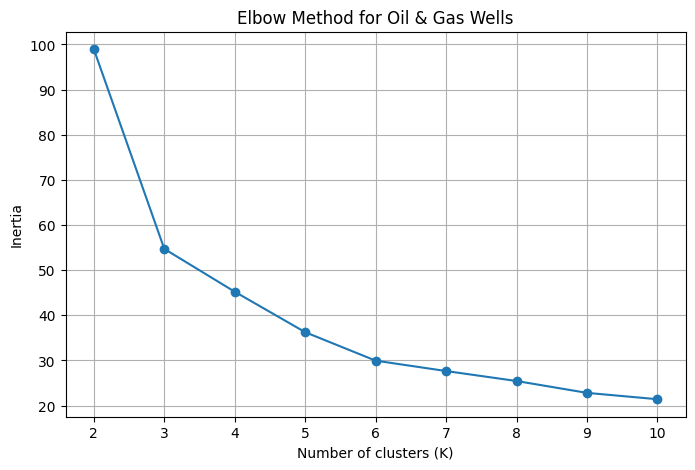

In [17]:
from sklearn.cluster import KMeans
import matplotlib.pyplot as plt

inertias = []
k_values = range(2, 11)

for k in k_values:
    model = KMeans(
        n_clusters=k,
        random_state=42,
        n_init=15
    )
    model.fit(X_scaled)
    inertias.append(model.inertia_)

plt.figure(figsize=(8, 5))
plt.plot(k_values, inertias, marker="o")
plt.xlabel("Number of clusters (K)")
plt.ylabel("Inertia")
plt.title("Elbow Method for Oil & Gas Wells")
plt.xticks(list(k_values))
plt.grid(True)
plt.show()

### Review Inertia Values

Print the inertia for each candidate value of K to support interpretation of the elbow plot.

In [ ]:
for k, inertia in zip(range(2, 11), inertias):
    print(f"K = {k}, Inertia = {inertia:.2f}")

K = 2, Inertia = 98.94
K = 3, Inertia = 54.71
K = 4, Inertia = 45.22
K = 5, Inertia = 36.25
K = 6, Inertia = 29.95
K = 7, Inertia = 27.65
K = 8, Inertia = 25.44
K = 9, Inertia = 22.81
K = 10, Inertia = 21.41


### Compare the Reduction in Inertia

Calculate the change in inertia between adjacent candidate values of K. This can help identify where the marginal improvement starts to level off.

In [ ]:
for i in range(1, len(inertias)):
    drop = inertias[i - 1] - inertias[i]
    print(
        f"{i + 1} -> {i + 2}: "
        f"Inertia drops by {drop:.2f}"
    )

2 -> 3: Inertia drops by 44.23
3 -> 4: Inertia drops by 9.49
4 -> 5: Inertia drops by 8.96
5 -> 6: Inertia drops by 6.30
6 -> 7: Inertia drops by 2.30
7 -> 8: Inertia drops by 2.21
8 -> 9: Inertia drops by 2.63
9 -> 10: Inertia drops by 1.41


## 9. Evaluate Cluster Quality: Silhouette Score

The silhouette score compares how close a sample is to its own cluster with how far it is from the nearest alternative cluster. Scores range from -1 to 1; higher values generally indicate better-defined clusters. A single score should be considered alongside domain knowledge and cluster interpretability.

In [18]:
from sklearn.metrics import silhouette_score

score = silhouette_score(X_scaled, df["cluster"])

print("Silhouette Score for K=5:", round(score, 3))

Silhouette Score for K=5: 0.389


### Compare Silhouette Scores Across K

Calculate the silhouette score for each candidate cluster count from 2 through 10. The best score is useful evidence, but it should not be treated as the only criterion for selecting K.

In [19]:
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

for k in range(2, 11):
    model = KMeans(
        n_clusters=k,
        random_state=42,
        n_init=15
    )

    labels = model.fit_predict(X_scaled)
    score = silhouette_score(X_scaled, labels)

    print(f"K = {k}, Silhouette Score = {score:.3f}")

K = 2, Silhouette Score = 0.468
K = 3, Silhouette Score = 0.470
K = 4, Silhouette Score = 0.410
K = 5, Silhouette Score = 0.389
K = 6, Silhouette Score = 0.352
K = 7, Silhouette Score = 0.318
K = 8, Silhouette Score = 0.310
K = 9, Silhouette Score = 0.308
K = 10, Silhouette Score = 0.287


### Visualize Silhouette Scores

Plot the silhouette score

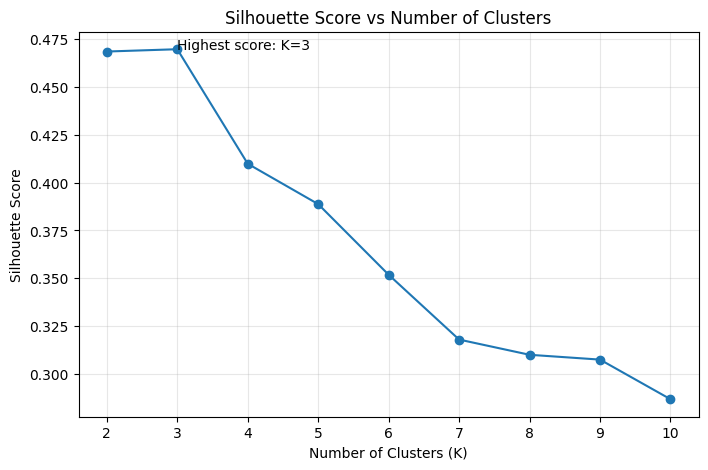

Silhouette Scores:
K = 2, Score = 0.468
K = 3, Score = 0.470
K = 4, Score = 0.410
K = 5, Score = 0.389
K = 6, Score = 0.352
K = 7, Score = 0.318
K = 8, Score = 0.310
K = 9, Score = 0.308
K = 10, Score = 0.287


In [20]:
import matplotlib.pyplot as plt
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

k_values = range(2, 11)
silhouette_scores = []

for k in k_values:
    model = KMeans(
        n_clusters=k,
        random_state=42,
        n_init=15
    )

    labels = model.fit_predict(X_scaled)

    score = silhouette_score(X_scaled, labels)
    silhouette_scores.append(score)

plt.figure(figsize=(8, 5))
plt.plot(k_values, silhouette_scores, marker="o")

plt.title("Silhouette Score vs Number of Clusters")
plt.xlabel("Number of Clusters (K)")
plt.ylabel("Silhouette Score")
plt.xticks(list(k_values))
plt.grid(True, alpha=0.3)

best_index = silhouette_scores.index(max(silhouette_scores))
best_k = list(k_values)[best_index]

plt.annotate(
    f"Highest score: K={best_k}",
    (best_k, silhouette_scores[best_index])
)

plt.show()

print("Silhouette Scores:")
for k, score in zip(k_values, silhouette_scores):
    print(f"K = {k}, Score = {score:.3f}")

## 10. PCA Visualization with Three Clusters

Fit a separate three-cluster K-Means model and display its labels in the existing two-component PCA projection. This compare a three-cluster solution with the earlier five-cluster model.

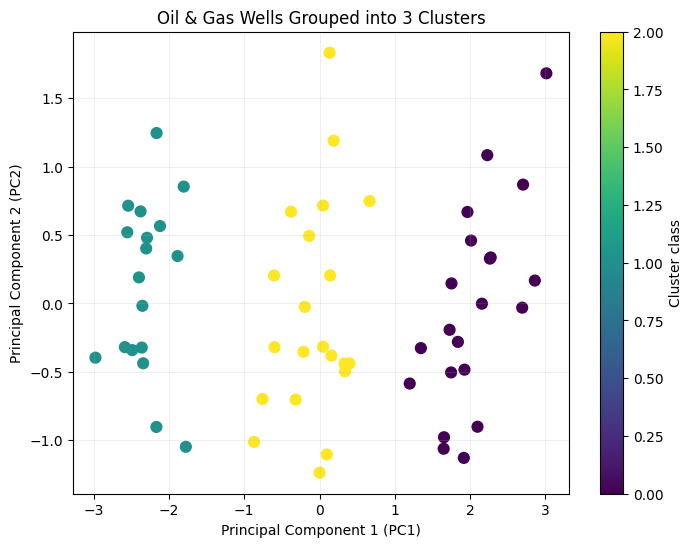

In [21]:
import matplotlib.pyplot as plt
from sklearn.cluster import KMeans


kmeans_3 = KMeans(
    n_clusters=3,
    random_state=42,
    n_init=15
)

labels_3 = kmeans_3.fit_predict(X_scaled)
#plot
plt.figure(figsize=(8, 6))

plt.scatter(
    X_pca[:, 0],
    X_pca[:, 1],
    c=labels_3,
    cmap="viridis",
    s=60
)

plt.title("Oil & Gas Wells Grouped into 3 Clusters")
plt.xlabel("Principal Component 1 (PC1)")
plt.ylabel("Principal Component 2 (PC2)")
plt.colorbar(label="Cluster class")
plt.grid(alpha=0.2)
plt.show()

### Visualize Cluster Centroids (additional)

Project the three-cluster model's centroids into the PCA coordinate system and display them alongside the wells. Centroids are shown in the reduced two-dimensional view for visualization; the model itself was fitted in the original standardized feature space.

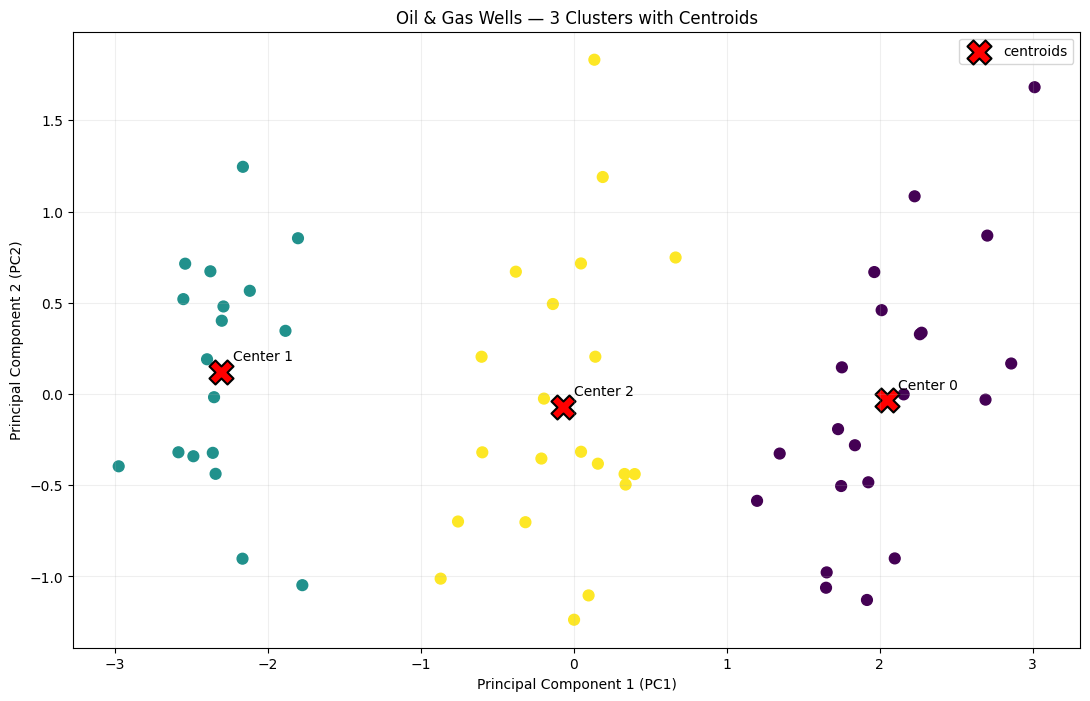

In [22]:
import matplotlib.pyplot as plt
from sklearn.cluster import KMeans
from sklearn.decomposition import PCA


pca = PCA(n_components=2)
X_pca = pca.fit_transform(X_scaled)


kmeans_3 = KMeans(
    n_clusters=3,
    random_state=42,
    n_init=15
)

labels_3 = kmeans_3.fit_predict(X_scaled)


centers_pca = pca.transform(kmeans_3.cluster_centers_)


plt.figure(figsize=(13, 8))

plt.scatter(
    X_pca[:, 0],
    X_pca[:, 1],
    c=labels_3,
    cmap="viridis",
    s=60,
)

plt.scatter(
    centers_pca[:, 0],
    centers_pca[:, 1],
    marker="X",
    s=300,
    c="red",
    edgecolors="black",
    linewidths=1.5,
    label="centroids"
)


for i, (x, y) in enumerate(centers_pca):
    plt.annotate(
        f"Center {i}",
        (x, y),
        xytext=(8, 8),
        textcoords="offset points"
    )

plt.title("Oil & Gas Wells — 3 Clusters with Centroids")
plt.xlabel("Principal Component 1 (PC1)")
plt.ylabel("Principal Component 2 (PC2)")
plt.legend()
plt.grid(alpha=0.2)
plt.show()